# US Accidents: cleaning and model results

This notebook presents the executed full-data cleaning audit, feature decisions, model comparison and held-out evaluation. Run `run_all.py` to rebuild the underlying artifacts; this notebook inspects the saved run.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "accidents").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from accidents.paths import PROCESSED, SPLITS, MODELS, REPORTS, DOCS
assert (REPORTS / "results.json").exists(), "Run python run_all.py --source <full CSV or ZIP> from the project root first."


In [2]:
from accidents.cleaning import FEATURES, DROP_REASONS
audit = json.loads((REPORTS / "cleaning.json").read_text(encoding="utf-8"))
display(pd.Series(audit["counts"], name="Recorded count").to_frame())
print(f"Retained events: {audit['clean_rows']:,}")
print("Source SHA-256:", audit["source_sha256"])


,Recorded count
input_rows,7728394
invalid_target_time_or_coordinates,0
invalid_Temperature(F),22
invalid_Humidity(%),0
invalid_Pressure(in),120
invalid_Visibility(mi),0
invalid_Wind_Speed(mph),21
invalid_Precipitation(in),0
weather_future,3787674
weather_stale_or_missing_time,137822


Retained events: 7,186,791
Source SHA-256: 9e1fe1bc00ab31432eb9cc3bb1dbf315f3aeaa17d61d61eb1f38c4c9a5fabf3f


## Missingness and leakage decisions

Missingness below describes the raw source. Missing numeric weather is retained for native tree handling; the linear candidate learns medians on training only. Future/stale weather is masked. Optional missing city/light fields remain usable.

In [3]:
missing = pd.Series(audit["raw_missing_counts"]).sort_values(ascending=False)
display(pd.DataFrame({"missing_count": missing, "raw_percent": 100 * missing / audit["counts"]["input_rows"]}))
display(pd.Series(DROP_REASONS, name="Exclusion reason").to_frame())


,missing_count,raw_percent
End_Lng,3402762,44.029355
End_Lat,3402762,44.029355
Precipitation(in),2203586,28.512858
Wind_Chill(F),1999019,25.865904
Wind_Speed(mph),571233,7.391355
Visibility(mi),177098,2.291524
Wind_Direction,175206,2.267043
Humidity(%),174144,2.253301
Weather_Condition,173459,2.244438
Temperature(F),163853,2.120143


,Exclusion reason
End_Time,Known after the accident: outcome leakage.
End_Lat,End-of-incident extent: outcome leakage.
End_Lng,End-of-incident extent: outcome leakage.
Distance(mi),Reported affected extent may encode outcome.
Description,Narrative can describe outcome and closure.
ID,"Identifier, retained only for traceability."
Source,Reporting-provider shortcut; retained only for...
Weather_Timestamp,Used only to reject future/stale observations.
Wind_Chill(F),"Redundant derived temperature, often absent."
Zipcode,Redundant high-cardinality location identifier.


## Inspect the cleaned schema

Only the first 1,000 rows are loaded for a schema preview; this preview is not a representative EDA sample. All class counts below come from the complete ingestion manifest.

In [4]:
preview = next(pq.ParquetFile(PROCESSED / "cleaned.parquet").iter_batches(batch_size=1000)).to_pandas()
display(preview.head())
display(preview.dtypes.astype(str).to_frame("type"))
print("Model inputs:", len(FEATURES))


,Start_Lat,Start_Lng,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Amenity,Bump,...,County,Weather_Group,Wind_Direction,Sunrise_Sunset,ID,Source,Severity,Start_Time,event_hash,row_number
0,39.865147,-84.058723,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,...,Montgomery,Unknown,Unknown,Night,A-1,Source2,3,2016-02-08 05:46:00,4706635164137012823,0
1,39.928059,-82.831184,37.900002,100.0,29.65,10.0,NaN,0.0,0.0,0.0,...,Franklin,Rain,CALM,Night,A-2,Source2,2,2016-02-08 06:07:59,8448417953698650210,1
2,39.063148,-84.032608,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,...,Clermont,Unknown,Unknown,Night,A-3,Source2,2,2016-02-08 06:49:27,10511704230218273308,2
3,39.747753,-84.205582,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,...,Montgomery,Unknown,Unknown,Night,A-4,Source2,3,2016-02-08 07:23:34,16611523704277335912,3
4,39.627781,-84.188354,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,...,Montgomery,Unknown,Unknown,Day,A-5,Source2,2,2016-02-08 07:39:07,16999383691607558899,4


,type
Start_Lat,float32
Start_Lng,float32
Temperature(F),float32
Humidity(%),float32
Pressure(in),float32
Visibility(mi),float32
Wind_Speed(mph),float32
Precipitation(in),float32
Amenity,float32
Bump,float32


Model inputs: 36


,count,share
1,64390,0.008959
2,5655378,0.786913
3,1290155,0.179518
4,176868,0.024610


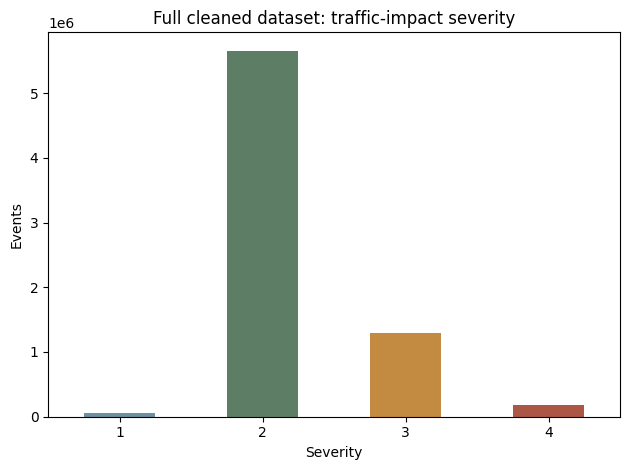

In [5]:
import matplotlib.pyplot as plt
counts = pd.Series(audit["class_counts"], dtype="int64")
display(pd.DataFrame({"count": counts, "share": counts / counts.sum()}))
ax = counts.plot.bar(color=["#6c91a1", "#5d7d64", "#c38a41", "#ac5746"], rot=0)
ax.set(title="Full cleaned dataset: traffic-impact severity", xlabel="Severity", ylabel="Events")
plt.tight_layout()
plt.show()


## Corrections and assumptions

No target imputation, full-data scaling, label-encoded nominal predictor ordering or outcome-column predictors remain. The audit describes the conservative event key and historical availability limits.

In [6]:
display(Markdown((DOCS / "code_audit.md").read_text(encoding="utf-8")))

# Code and cleaning audit

Reviewed both root notebooks, their identical copies in `Data Science Project/`, both READMEs and the 19-page midterm PDF. The checkout initially contained no CSV, Parquet, Python modules or fitted models. The full source archive was found in Downloads and selected by the user.

| Location | Problem | Correction |
|---|---|---|
| `omar_ml_pipeline.ipynb`, cell 3 | Numeric medians and categorical modes fitted on all rows, including test; target could be imputed | Never impute labels. Fit all learned transformations inside training pipelines; LightGBM handles numeric missingness natively. |
| Same, cell 4 | LabelEncoder on all categorical predictors creates arbitrary ordinal meanings and learns test categories | Training-only vocabulary; mark encoded columns as native categorical features for LightGBM. Train-only one-hot encoding for logistic regression. |
| Same, cells 4–6 | ID, Description, Distance and endpoint coordinates enter models | Explicit feature allowlist excludes identifiers, outcome fields and provider Source. |
| Same, cell 6 | Severity used for regression and median-based binary classification; missing target silently replaced by first numeric column | Require Severity 1–4 and use multiclass classification. Preserve all four categories. |
| Same, cells 7–9 | Several models compared directly on test accuracy; regressor feature importance used for a different task | Select by development macro F1; evaluate final classifier once on 20%; explain selected classifier using validation permutation importance. |
| `pipeline.ipynb`, cells 13–14, 34 | Rows dropped for missing City/Zipcode; full-data median/scaling | Keep rows with optional fields missing; Unknown categories; train-only preprocessing. |
| Same, cell 31 | Mixed datetime precision can silently turn valid rows into NaT | Explicit mixed parsing and fixed nanosecond dtype across chunks. |
| All notebooks | Exact-row duplication with ID misses repeated records; no fixed event separation | Deduplicate exact time/coordinate event keys across all chunks before splitting; save IDs and row indices. |
| README/PDF | Missing precipitation described as zero; weather timestamp discarded without availability check | Leave precipitation missing with indicator; mask observations after start, older than three hours, or missing timestamp. |
| README/PDF | Temperature thresholds could erase plausible extremes | Conservative physical ranges; no quantile trimming. Record every invalid-value count. |
| Midterm PDF | References absent `src/features.py`, `run_all.py` and six notebooks; old sample counts cannot be reproduced here | Preserve original PDF; new shared modules, corrected entry notebooks and reports generated from the full-data run. |

## Design decisions

Severity describes ordered traffic-impact categories, not a continuous measured quantity. Multiclass classification retains the original task and allows per-class recall. Macro F1 gives all four classes equal weight; accuracy is shown alongside the majority baseline.

Use a seeded, stratified 80/20 development/test split after deterministic row-local cleaning and event deduplication. Split development again for candidate selection. Tune on representative bounded subsets, freeze model/weights/iteration count using validation, then refit on the entire 80%. No resampling or preprocessing is fitted on test. The temporal diagnostic uses development records only and is not a selection criterion.

Numeric missingness is native for trees; the linear pipeline fits medians, indicators, scaling and one-hot encoding on training only. Categorical codes in LightGBM are explicitly flagged categorical, not treated as ordered numbers. City and County are qualified with State in the encoder. Missing categories and unseen categories are handled explicitly.

Deduplication conservatively keeps the first row with identical local start time and original-precision coordinates, regardless of ID/provider/label. Coincident independent incidents may be merged; nearby events with different timestamps can remain correlated. This policy trades some coverage for preventing exact-event contamination. A 64-bit event hash has a negligible nonzero collision probability.

Weather cutoff is a documented operational assumption, not proof of original ingestion timing. Historical road-map enrichment may also differ from what was available at report time. Excluding Source reduces a direct reporting shortcut, but location and year can still proxy providers. A random holdout is not an estimate of deployment performance on future years.

## References

- Dataset and original definition: [Moosavi et al., A Countrywide Traffic Accident Dataset](https://arxiv.org/abs/1906.05409).
- [LightGBM classifier documentation](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html), including categorical support and warnings about probability estimates under class weighting.


## Model selection and evaluation

The original four severity classes are retained. Selection uses validation macro F1; the selected model is refitted on the full 80% development partition and evaluated on the untouched 20%.

In [7]:
results = json.loads((REPORTS / "results.json").read_text(encoding="utf-8"))
print("Chosen model:", results["selected_model"])
print(f"Development: {results['development_rows']:,}; test: {results['test_rows']:,}")
comparison = pd.DataFrame(results["validation_models"])
display(comparison[["name", "macro_f1", "balanced_accuracy", "accuracy", "seconds"]].sort_values("macro_f1", ascending=False))


Chosen model: LightGBM · deeper trees
Development: 5,749,432; test: 1,437,359


,name,macro_f1,balanced_accuracy,accuracy,seconds
4,LightGBM · deeper trees,0.573889,0.610860,0.822406,176.404029
3,LightGBM · moderate weights,0.563601,0.624864,0.816237,135.524732
2,LightGBM · natural,0.535547,0.487283,0.843919,139.157995
5,LightGBM · balanced,0.527009,0.665649,0.753012,312.033394
1,Logistic regression,0.335602,0.613173,0.492200,28.783159
0,Majority baseline,0.220188,0.250000,0.786913,0.000000


## Untouched test performance

Accuracy alone is misleading under the large class imbalance. Inspect macro F1 and every class recall, including severity 1 and 4.

,Test score
accuracy,0.828335
macro_f1,0.592185
balanced_accuracy,0.684780
weighted_f1,0.835759
log_loss,0.436118
roc_auc_ovr_macro,0.915112


,precision,recall,f1-score,support
1,0.334897,0.775975,0.467870,1.287800e+04
2,0.924022,0.868721,0.895519,1.131076e+06
3,0.611257,0.715530,0.659296,2.580310e+05
4,0.318452,0.378894,0.346054,3.537400e+04
accuracy,0.828335,0.828335,0.828335,8.283352e-01
macro avg,0.547157,0.684780,0.592185,1.437359e+06
weighted avg,0.847694,0.828335,0.835759,1.437359e+06


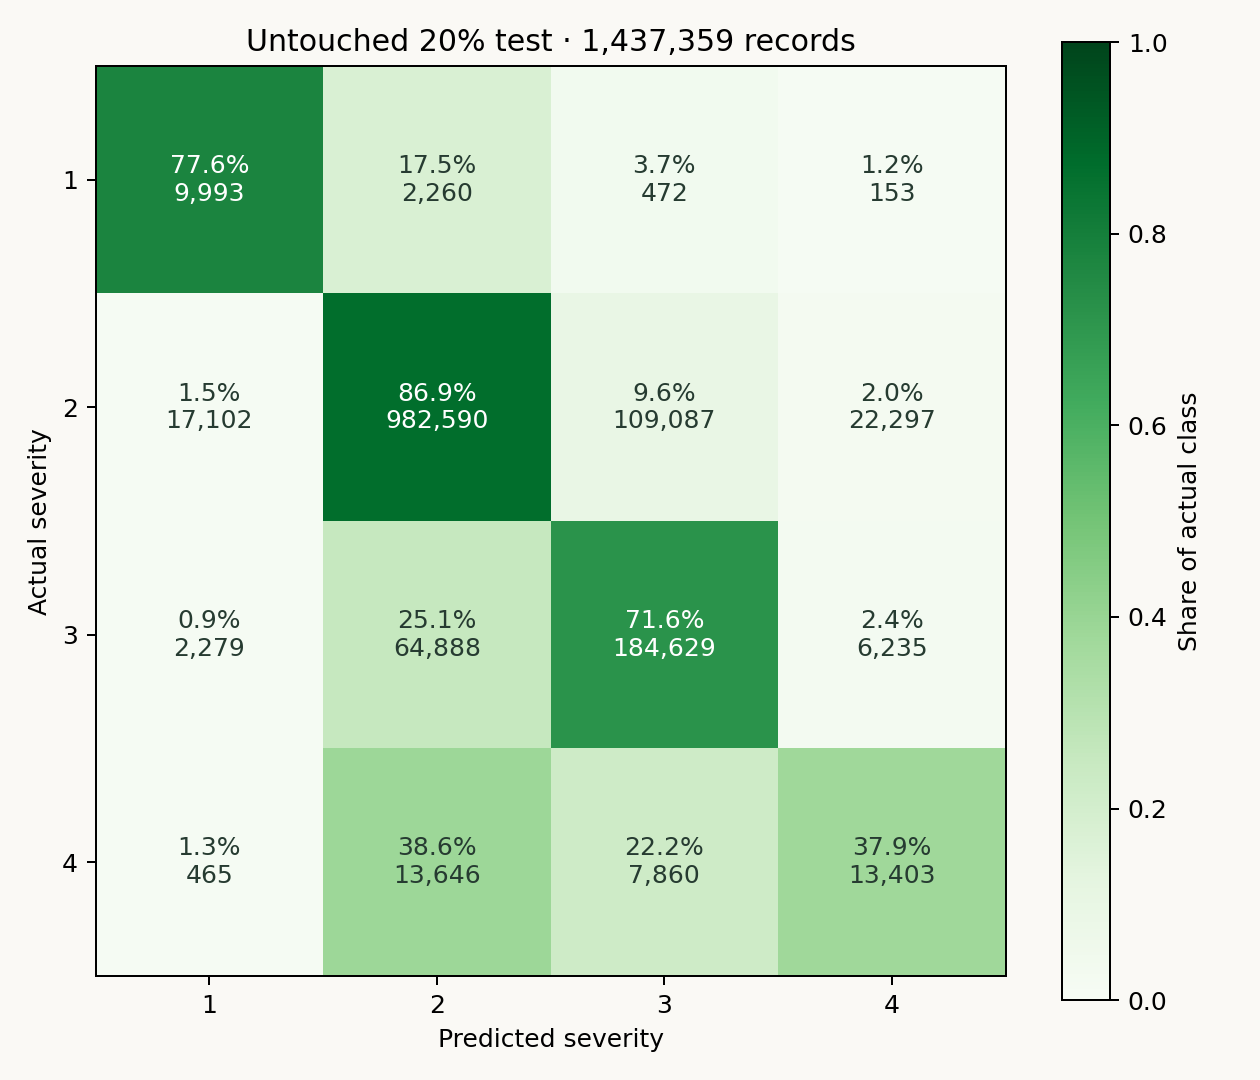

In [8]:
display(pd.Series({k:v for k,v in results["test"].items() if isinstance(v, (int, float))}).to_frame("Test score"))
display(pd.DataFrame(results["test"]["classification_report"]).T)
display(Image(filename=str(REPORTS / "figures" / "confusion_matrix.png")))


## Load the saved model and verify actual test predictions

These are test rows from the first Parquet row group. The fitted category vocabulary is reused; nothing is refitted here.

In [9]:
import joblib
from accidents.cleaning import FEATURES
splits = np.load(SPLITS / "splits.npz")
block = pq.ParquetFile(PROCESSED / "cleaned.parquet").read_row_group(0).to_pandas()
indices = splits["test"][splits["test"] < len(block)][:10]
sample = block.iloc[indices].copy()
model = joblib.load(MODELS / "severity.joblib")
sample["predicted"] = model.predict(sample[FEATURES])
sample["model_score"] = model.predict_proba(sample[FEATURES]).max(axis=1)
display(sample[["ID", "Start_Time", "State", "City", "Severity", "predicted", "model_score"]])


C:\Users\youss\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\youss\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,ID,Start_Time,State,City,Severity,predicted,model_score
83303,A-83338,2016-10-12 12:13:24,CA,Capistrano Beach,3,3,0.766022
38542,A-38554,2016-05-16 13:16:38,CA,American Canyon,3,3,0.742223
156511,A-156640,2016-08-24 09:57:35,GA,Atlanta,2,3,0.801437
37672,A-37683,2016-05-05 20:36:30,CA,Mountain View,2,2,0.914981
179311,A-179454,2016-12-07 15:46:25,MI,Detroit,3,3,0.737801
1637,A-1638,2016-06-29 10:07:57,CA,San Bruno,3,3,0.751098
147062,A-147169,2016-12-12 22:05:24,SC,Batesburg,3,3,0.930311
29375,A-29381,2016-08-31 09:48:16,CA,Moss Landing,2,2,0.941404
40787,A-40802,2016-06-01 15:21:01,CA,Stockton,2,2,0.689335
194484,A-194644,2016-12-02 15:23:42,NY,Canaan,2,2,0.876925


## Temporal robustness and interpretation

The temporal check uses development data only, before versus from 2022. Permutation importance describes predictive reliance of the development model and is not causal evidence. Class-weighted scores are uncalibrated.

,Temporal check
cutoff,2022-01-01
scope,"Development only; diagnostic, not used for mod..."
train_rows,600000
evaluation_rows,160000
accuracy,0.859169
macro_f1,0.327396
balanced_accuracy,0.342636
weighted_f1,0.858135


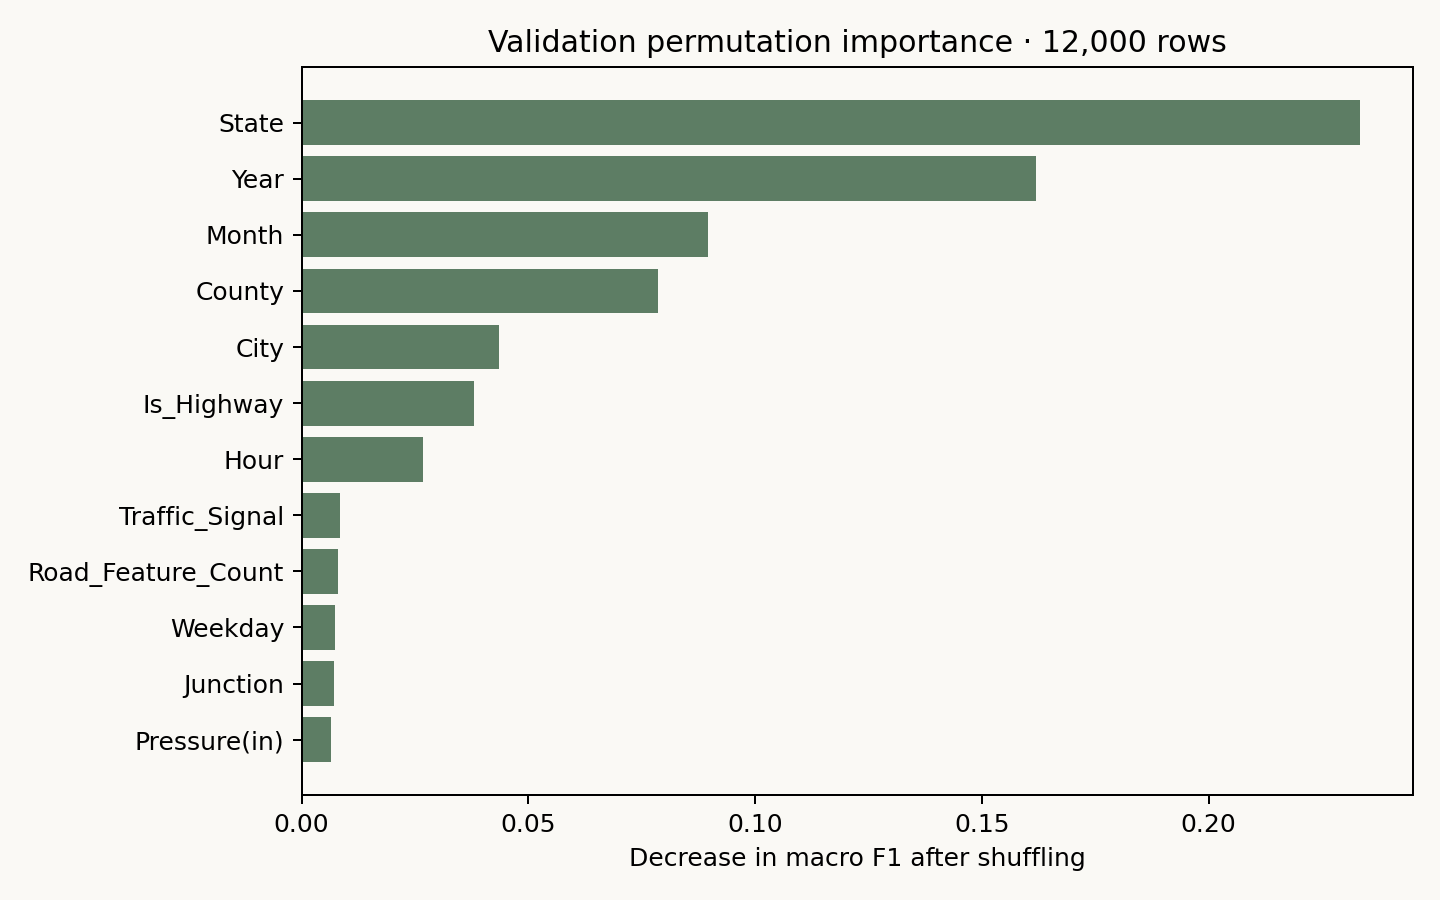

# Full-data severity classification results

The target is the original four-class traffic-impact Severity. It is not injury severity, delay duration, or accident occurrence probability.

Selected model: **LightGBM · deeper trees**, by validation macro F1. Test macro F1: **0.5922**; accuracy: **82.83%**; balanced accuracy: **68.48%**.

## Data and cleaning

The entire archive contains 7,728,394 records. 541,603 repeated exact time/coordinate events were removed, leaving 7,186,791. Final training used 5,749,432 rows and the untouched 20% test used 1,437,359 rows (ceiling rounding).

Raw weather observations after accident start were masked on 3,787,674 rows. Stale (>3 hours) or missing-timestamp weather was masked on 137,822 rows. Counts are before deduplication. Missing precipitation is not changed to zero. Optional missing location/light categories do not cause row deletion.

See [code audit](code_audit.md) and [machine-readable cleaning log](../outputs/reports/cleaning.json) for the corrections, physical thresholds, event-key policy and feature exclusions.

## Selection protocol

Seed 42. A stratified 80/20 split is created after deterministic cleaning and duplicate removal. Development is split again 80/20; capped stratified subsets of 600,000 fitting and 160,000 validation records are used for every candidate. Category vocabularies, numeric medians and scalers learn only from fitting data. Native categorical codes are flagged categorical for LightGBM. No outcome columns or Source are predictors.

Tree size, class weighting and early stopping are selected by validation macro F1; the best candidate is refitted on all development rows with its selected iteration count. Test evaluation follows once. This is a practical bounded search, not proof of a global optimum.

| Candidate | Validation macro F1 | Balanced accuracy | Severity 4 recall | Fit + validation seconds |
|---|---:|---:|---:|---:|
| Majority baseline | 0.2202 | 0.2500 | 0.0000 | 0.0 |
| Logistic regression | 0.3356 | 0.6132 | 0.5767 | 28.8 |
| LightGBM · natural | 0.5355 | 0.4873 | 0.1092 | 139.2 |
| LightGBM · moderate weights | 0.5636 | 0.6249 | 0.3085 | 135.5 |
| LightGBM · deeper trees | 0.5739 | 0.6109 | 0.2941 | 176.4 |
| LightGBM · balanced | 0.5270 | 0.6656 | 0.4418 | 312.0 |

## Untouched test evaluation

Majority baseline macro F1: 0.2202; accuracy: 78.69%. Selected model macro F1: 0.5922; weighted F1: 0.8358; macro OvR ROC-AUC: 0.9151; log loss: 0.4361.

| Severity | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| 1 | 0.3349 | 0.7760 | 0.4679 | 12,878 |
| 2 | 0.9240 | 0.8687 | 0.8955 | 1,131,076 |
| 3 | 0.6113 | 0.7155 | 0.6593 | 258,031 |
| 4 | 0.3185 | 0.3789 | 0.3461 | 35,374 |

![Test confusion matrix](../outputs/reports/figures/confusion_matrix.png)

## Temporal robustness

A separate development-only diagnostic trains on up to 600,000 records before 2022 and evaluates on up to 160,000 records from 2022 onward. Its macro F1 is 0.3274. This is a different distribution and a smaller training sample than the final refit; it is not a second evaluation of the final model. It was not used for selection.

## Interpretation

Validation permutation importance uses one shuffle per feature on 12,000 validation records of the selected development model. Importance measures predictive reliance, not causal influence. Correlated predictors can share importance.

![Validation permutation importance](../outputs/reports/figures/importance.png)

## Limitations

- Severity is traffic impact, not injury severity or accident probability.
- The random holdout estimates performance on the same historical distribution; nearby incidents may remain correlated.
- Training and test labels reflect provider conventions, even though Source is excluded as a feature.
- Weather availability is checked against start time; historical data ingestion timing and later road-map updates are unverified.
- Class-weighted model scores are not calibrated probabilities.
- Hyperparameters and iteration count were selected on development subsets; no claim of a globally optimal model.
- The data ends in March 2023 and does not establish current-road performance.

## Reproducibility

Source archive SHA-256: `9e1fe1bc00ab31432eb9cc3bb1dbf315f3aeaa17d61d61eb1f38c4c9a5fabf3f`.
Versions: `{"python": "3.14.0", "numpy": "2.4.4", "pandas": "3.0.2", "sklearn": "1.9.1", "lightgbm": "4.6.0"}`.

Artifacts: `data/processed/cleaned.parquet`, `data/processed/row_manifest.npz`, `data/splits/splits.npz`, `outputs/models/severity.joblib`, `data/predictions/test_predictions.parquet`, `data/predictions/test_predictions.csv.gz`, and `dashboard/dist/data/`.

Original source: [Moosavi et al.](https://arxiv.org/abs/1906.05409). [LightGBM documentation](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html). The original `outputs/archive/midterm_report.pdf` describes earlier sample-based work and is preserved as a historical artifact.


In [10]:
display(pd.Series({k:v for k,v in results["temporal"].items() if not isinstance(v,(list,dict))}).to_frame("Temporal check"))
display(Image(filename=str(REPORTS / "figures" / "importance.png")))
display(Markdown((DOCS / "results.md").read_text(encoding="utf-8")))
